In [1]:

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

In [2]:
df = pd.read_csv("laptop_data.csv")
df.head()

,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


In [3]:
df = df.drop('Unnamed: 0',axis=1)
df.head()

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


In [4]:
df.isnull().sum()

Company             0
TypeName            0
Inches              0
ScreenResolution    0
Cpu                 0
Ram                 0
Memory              0
Gpu                 0
OpSys               0
Weight              0
Price               0
dtype: int64

In [5]:
df['Ram'] = df['Ram'].str.replace("GB","").astype(int)
df['Weight'] = df['Weight'].str.replace("kg","").astype(float)

In [6]:
df.head()

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,71378.6832
1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,47895.5232
2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,No OS,1.86,30636.0000
3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16,512GB SSD,AMD Radeon Pro 455,macOS,1.83,135195.3360
4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,96095.8080


In [7]:
df["IPs"] = df['ScreenResolution'].str.contains("IPS").astype(int)
df["TouchScreen"] = df['ScreenResolution'].str.contains("Touch").astype(int)
df["X_res"] = df["ScreenResolution"].str.extract(r'(\d+)x').astype(int)

df["Y_res"] = df["ScreenResolution"].str.extract(r'x(\d+)').astype(int)

df.drop(columns=("ScreenResolution"),inplace=True)

In [8]:
df.head()

,Company,TypeName,Inches,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price,IPs,TouchScreen,X_res,Y_res
0,Apple,Ultrabook,13.3,Intel Core i5 2.3GHz,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,71378.6832,1,0,2560,1600
1,Apple,Ultrabook,13.3,Intel Core i5 1.8GHz,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,47895.5232,0,0,1440,900
2,HP,Notebook,15.6,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,No OS,1.86,30636.0000,0,0,1920,1080
3,Apple,Ultrabook,15.4,Intel Core i7 2.7GHz,16,512GB SSD,AMD Radeon Pro 455,macOS,1.83,135195.3360,1,0,2880,1800
4,Apple,Ultrabook,13.3,Intel Core i5 3.1GHz,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,96095.8080,1,0,2560,1600


In [9]:
df["CPU_Brand"] = df["Cpu"].apply(lambda x: x.split()[0])

df["ClockSpeed"] = df["Cpu"].str.extract(r'(\d+\.\d+)GHz').astype(float)

df.drop(columns="Cpu", inplace=True)

In [10]:
df["GPU_Brand"] = df["Gpu"].apply(lambda x: x.split()[0])
df.drop(columns="Gpu", inplace=True)

In [11]:
categorical_cols = [
    "Company",
    "TypeName",
    "OpSys",
    "CPU_Brand",
    "GPU_Brand"
]

df = pd.get_dummies(
    df,
    columns=categorical_cols,
    drop_first=True
)

In [12]:
df.head()

,Inches,Ram,Memory,Weight,Price,IPs,TouchScreen,X_res,Y_res,ClockSpeed,...,OpSys_No OS,OpSys_Windows 10,OpSys_Windows 10 S,OpSys_Windows 7,OpSys_macOS,CPU_Brand_Intel,CPU_Brand_Samsung,GPU_Brand_ARM,GPU_Brand_Intel,GPU_Brand_Nvidia
0,13.3,8,128GB SSD,1.37,71378.6832,1,0,2560,1600,2.3,...,False,False,False,False,True,True,False,False,True,False
1,13.3,8,128GB Flash Storage,1.34,47895.5232,0,0,1440,900,1.8,...,False,False,False,False,True,True,False,False,True,False
2,15.6,8,256GB SSD,1.86,30636.0000,0,0,1920,1080,2.5,...,True,False,False,False,False,True,False,False,True,False
3,15.4,16,512GB SSD,1.83,135195.3360,1,0,2880,1800,2.7,...,False,False,False,False,True,True,False,False,False,False
4,13.3,8,256GB SSD,1.37,96095.8080,1,0,2560,1600,3.1,...,False,False,False,False,True,True,False,False,True,False


In [13]:
df.dtypes

Inches                  float64
Ram                       int64
Memory                   object
Weight                  float64
Price                   float64
IPs                       int64
TouchScreen               int64
X_res                     int64
Y_res                     int64
ClockSpeed              float64
Company_Apple              bool
Company_Asus               bool
Company_Chuwi              bool
Company_Dell               bool
Company_Fujitsu            bool
Company_Google             bool
Company_HP                 bool
Company_Huawei             bool
Company_LG                 bool
Company_Lenovo             bool
Company_MSI                bool
Company_Mediacom           bool
Company_Microsoft          bool
Company_Razer              bool
Company_Samsung            bool
Company_Toshiba            bool
Company_Vero               bool
Company_Xiaomi             bool
TypeName_Gaming            bool
TypeName_Netbook           bool
TypeName_Notebook          bool
TypeName

In [14]:
df[df.select_dtypes("bool").columns] = (
    df.select_dtypes("bool").astype(int)
)

In [15]:
df.head()

,Inches,Ram,Memory,Weight,Price,IPs,TouchScreen,X_res,Y_res,ClockSpeed,...,OpSys_No OS,OpSys_Windows 10,OpSys_Windows 10 S,OpSys_Windows 7,OpSys_macOS,CPU_Brand_Intel,CPU_Brand_Samsung,GPU_Brand_ARM,GPU_Brand_Intel,GPU_Brand_Nvidia
0,13.3,8,128GB SSD,1.37,71378.6832,1,0,2560,1600,2.3,...,0,0,0,0,1,1,0,0,1,0
1,13.3,8,128GB Flash Storage,1.34,47895.5232,0,0,1440,900,1.8,...,0,0,0,0,1,1,0,0,1,0
2,15.6,8,256GB SSD,1.86,30636.0000,0,0,1920,1080,2.5,...,1,0,0,0,0,1,0,0,1,0
3,15.4,16,512GB SSD,1.83,135195.3360,1,0,2880,1800,2.7,...,0,0,0,0,1,1,0,0,0,0
4,13.3,8,256GB SSD,1.37,96095.8080,1,0,2560,1600,3.1,...,0,0,0,0,1,1,0,0,1,0


In [16]:
df["Memory"] = df["Memory"].str.replace("TB", "000GB")

df["SSD"] = 0
df["HDD"] = 0
df["Flash"] = 0
df["Hybrid"] = 0


import re

for i, memory in enumerate(df["Memory"]):

    if "SSD" in memory:
        match = re.search(r"(\d+)GB SSD", memory)
        if match:
            df.loc[i, "SSD"] = int(match.group(1))

    if "HDD" in memory:
        match = re.search(r"(\d+)GB HDD", memory)
        if match:
            df.loc[i, "HDD"] = int(match.group(1))

    if "Flash Storage" in memory:
        match = re.search(r"(\d+)GB Flash Storage", memory)
        if match:
            df.loc[i, "Flash"] = int(match.group(1))

    if "Hybrid" in memory:
        match = re.search(r"(\d+)GB Hybrid", memory)
        if match:
            df.loc[i, "Hybrid"] = int(match.group(1))

df.drop(columns="Memory", inplace=True)

In [17]:
df["Total_Storage"] = (
    df["SSD"] +
    df["HDD"] +
    df["Flash"] +
    df["Hybrid"]
)

In [18]:
x = df.drop('Price',axis= 1)
y =df['Price']

In [19]:
x.isnull().sum()
x['ClockSpeed'] = x['ClockSpeed'].fillna(df['ClockSpeed'].mean())

In [20]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(x,y,test_size=0.2 ,random_state=42)

In [21]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [22]:
from sklearn.neighbors import KNeighborsRegressor

knn = KNeighborsRegressor(n_neighbors=2)

knn.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",2
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


In [23]:
y_pred = knn.predict(X_test_scaled)

In [24]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 12425.847282758621
RMSE: 19455.524116301553
R2 Score: 0.7374835368909928


In [25]:
scores = []

for i in range(1,16):
    
    knn = KNeighborsRegressor(n_neighbors=i)
    
    knn.fit(X_train_scaled,y_train)
    
    y_pred = knn.predict(X_test_scaled)

    scores.append(r2_score(y_test, y_pred))

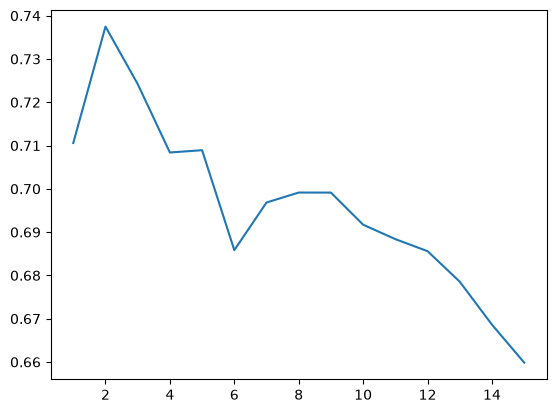

In [26]:
import matplotlib.pyplot as plt

plt.plot(range(1,16),scores)